In [22]:
# Import libraries
import os
from pathlib import Path
import cv2


In [23]:
# Block1: Read the pet facial expression dataset from local disk.
# Supports launching Jupyter from the repository root or the lab_vgg folder.
dataset_candidates = [
    Path.cwd() / "pet_facial_expression_dataset",
    Path.cwd() / "lab_vgg" / "pet_facial_expression_dataset",
]
dataset_dir = next((path.resolve() for path in dataset_candidates if path.is_dir()), None)
if dataset_dir is None:
    raise FileNotFoundError(
        "Cannot find pet_facial_expression_dataset. Start Jupyter from the repository root or lab_vgg."
    )

# Folder names are the class labels; keep this order for training and inference.
class_names = sorted(path.name for path in dataset_dir.iterdir() if path.is_dir())
num_classes = len(class_names)
if num_classes < 2:
    raise ValueError("The dataset must contain at least two class folders.")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
max_images_per_class = 2000
images_by_class = {}
for class_name in class_names:
    files = sorted(
        path.name for path in (dataset_dir / class_name).iterdir()
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    images_by_class[class_name] = files[:max_images_per_class]
    print(f"{class_name}: {len(files)} images, using {len(images_by_class[class_name])}")

print("Dataset:", dataset_dir)
print("Class labels:", dict(enumerate(class_names)))


Angry: 250 images, using 250
Other: 250 images, using 250
Sad: 250 images, using 250
happy: 250 images, using 250
Dataset: C:\Users\Pc\Documents\GitHub\AI_class\lab_vgg\pet_facial_expression_dataset
Class labels: {0: 'Angry', 1: 'Other', 2: 'Sad', 3: 'happy'}


In [24]:
# Block2: Define Functions
def save_images(file_list, src_dir, dst_dir):
    target_size=(256,256)
    for filename in file_list:
        src_path = os.path.join(src_dir, filename)
        dst_path = os.path.join(dst_dir, filename)

        try:
            img = cv2.imread(src_path)
            if img is None: 
                continue
            
            img = cv2.resize(img, target_size)
            cv2.imwrite(dst_path, img)
        except:
            continue

def make_dir(path):
    if not os.path.exists(path):
        os.makedirs(path)

In [25]:
# Block3: Split each expression class into train/validation/test sets.
from sklearn.model_selection import train_test_split

test_ratio = 0.15
val_ratio = 0.15
splits = {"train": {}, "validation": {}, "test": {}}
for class_name, filenames in images_by_class.items():
    train_files, temp_files = train_test_split(
        filenames, test_size=test_ratio + val_ratio, random_state=42
    )
    val_files, test_files = train_test_split(
        temp_files, test_size=test_ratio / (test_ratio + val_ratio), random_state=42
    )
    splits["train"][class_name] = train_files
    splits["validation"][class_name] = val_files
    splits["test"][class_name] = test_files
    print(f"{class_name}: train={len(train_files)}, validation={len(val_files)}, test={len(test_files)}")


Angry: train=175, validation=37, test=38
Other: train=175, validation=37, test=38
Sad: train=175, validation=37, test=38
happy: train=175, validation=37, test=38


In [26]:
# Block4: Create output folders beside the source dataset.
output_dir = dataset_dir.parent / "preprocess_pet_facial_expression_dataset"
for split in splits:
    for class_name in class_names:
        make_dir(output_dir / split / class_name)


In [27]:
# Resize and save every expression class in each split.
for split, class_files in splits.items():
    for class_name, filenames in class_files.items():
        save_images(
            filenames,
            dataset_dir / class_name,
            output_dir / split / class_name,
        )

print("Preprocessing completed!", output_dir)


Preprocessing completed! C:\Users\Pc\Documents\GitHub\AI_class\lab_vgg\preprocess_pet_facial_expression_dataset


In [28]:
# Load the same images once; batching is applied separately for each run.
import csv
import json
import time
import tensorflow as tf
from IPython.display import Markdown, display

batch_sizes = [32, 64]
epochs = 10
seed = 42
img_size = (256, 256)
lab_dir = dataset_dir.parent
train_dir = output_dir / "train"
val_dir = output_dir / "validation"

# Keep RGB pixels in [0, 255]; VGG19 preprocessing is inside the model.
# Begin with ordered, unbatched samples so both runs use the same image split.
train_images = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir, labels="inferred", label_mode="int", class_names=class_names,
    batch_size=None, image_size=img_size, shuffle=False,
)
num_train_images = len(train_images.file_paths)
val_images = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir, labels="inferred", label_mode="int", class_names=class_names,
    batch_size=None, image_size=img_size, shuffle=False,
)

def make_datasets(batch_size):
    train_ds = train_images.shuffle(
        num_train_images, seed=seed, reshuffle_each_iteration=True
    ).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    val_ds = val_images.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return train_ds, val_ds

class_names_file = lab_dir / "pet_expression_class_names.json"
class_names_file.write_text(json.dumps(class_names, indent=2), encoding="utf-8")
print("Training batch sizes:", batch_sizes)


Found 700 files belonging to 4 classes.


Found 148 files belonging to 4 classes.
Training batch sizes: [32, 64]


In [29]:
# Identical VGG19 architecture is defined inside the test notebook.
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.optimizers import Adam


IMAGE_SIZE = (256, 256)


def build_vgg19_model(num_classes, weights="imagenet"):
    """Accept RGB pixels in [0, 255]; use weights=None before loading saved weights."""
    if num_classes < 2:
        raise ValueError("At least two expression classes are required.")

    base_model = VGG19(
        include_top=False,
        weights=weights,
        input_shape=(*IMAGE_SIZE, 3),
    )
    base_model.trainable = False

    model = models.Sequential(
        [
            layers.Input(shape=(*IMAGE_SIZE, 3)),
            layers.Lambda(preprocess_input, name="vgg19_preprocessing"),
            base_model,
            layers.GlobalAveragePooling2D(),
            layers.Dense(128, activation="relu"),
            layers.Dropout(0.5),
            layers.Dense(num_classes, activation="softmax"),
        ],
        name="pet_expression_vgg19",
    )
    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


In [16]:
# Train independent models; reset the session and seed before each run.
# Keep architecture, starting seed, learning rate, epochs, and split fixed.
# These are final-epoch weights, saved immediately after each successful run.
histories = {}
training_results = []
for batch_size in batch_sizes:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    train_ds, val_ds = make_datasets(batch_size)
    model_vgg19 = build_vgg19_model(num_classes, weights="imagenet")
    if batch_size == batch_sizes[0]:
        model_vgg19.summary()
    print(f"\nTraining VGG19 with batch size {batch_size}")
    start_time = time.perf_counter()
    history = model_vgg19.fit(train_ds, validation_data=val_ds, epochs=epochs)
    training_seconds = time.perf_counter() - start_time

    weights_file = lab_dir / f"TL_VGG19_pet_expression_batch{batch_size}.weights.h5"
    model_vgg19.save_weights(str(weights_file))
    histories[batch_size] = {
        name: [float(value) for value in values]
        for name, values in history.history.items()
    }
    result = {
        "batch_size": batch_size,
        "epochs": epochs,
        "seed": seed,
        "learning_rate": 0.0001,
        "train_accuracy": histories[batch_size]["accuracy"][-1],
        "val_accuracy": histories[batch_size]["val_accuracy"][-1],
        "train_loss": histories[batch_size]["loss"][-1],
        "val_loss": histories[batch_size]["val_loss"][-1],
        "training_seconds": training_seconds,
        "weights_file": weights_file.name,
    }
    training_results.append(result)
    history_file = lab_dir / f"VGG19_batch{batch_size}_history.json"
    history_file.write_text(
        json.dumps({"summary": result, "history": histories[batch_size]}, indent=2),
        encoding="utf-8",
    )
    print(f"Saved weights: {weights_file}")
    print(f"Saved history: {history_file}")
    # Release the model before starting the next batch-size experiment.
    del model_vgg19, history, train_ds, val_ds



80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 119s 1us/step


Model: "pet_expression_vgg19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19_preprocessing (Lambda)    │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,090,564 (76.64 MB)

 Trainable params: 66,180 (258.52 KB)

 Non-trainable params: 20,024,384 (76.39 MB)


Training VGG19 with batch size 32
Epoch 1/10


c:\Users\Pc\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


22/22 ━━━━━━━━━━━━━━━━━━━━ 50s 2s/step - accuracy: 0.2829 - loss: 6.9426 - val_accuracy: 0.3243 - val_loss: 3.1972
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 55s 3s/step - accuracy: 0.3071 - loss: 5.5543 - val_accuracy: 0.3784 - val_loss: 3.0130
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.3200 - loss: 5.0029 - val_accuracy: 0.3986 - val_loss: 2.7470
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 70s 3s/step - accuracy: 0.3714 - loss: 4.4668 - val_accuracy: 0.4122 - val_loss: 2.5823
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 50s 2s/step - accuracy: 0.3800 - loss: 4.0573 - val_accuracy: 0.4324 - val_loss: 2.3570
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.4214 - loss: 3.4194 - val_accuracy: 0.4324 - val_loss: 2.1836
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.4357 - loss: 2.8368 - val_accuracy: 0.4392 - val_loss: 2.0229
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.4371 - loss: 2.6357 - val_accuracy: 0.4392 - val_loss: 1.8825
Epo

In [30]:
# Compare final training/validation metrics and export the results.
comparison_file = lab_dir / "VGG19_batch_training_comparison.csv"
with comparison_file.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(training_results[0]))
    writer.writeheader()
    writer.writerows(training_results)

rows = [
    "| Batch size | Train accuracy | Validation accuracy | Train loss | Validation loss | Seconds |",
    "|---|---|---|---|---|---|",
]
for result in training_results:
    rows.append(
        f"| {result['batch_size']} | {result['train_accuracy']:.4f} | "
        f"{result['val_accuracy']:.4f} | {result['train_loss']:.4f} | "
        f"{result['val_loss']:.4f} | {result['training_seconds']:.1f} |"
    )
display(Markdown("\n".join(rows)))
print(f"Saved: {comparison_file}")
print("Run binary_classification_test.ipynb to compare held-out classification performance.")


| Batch size | Train accuracy | Validation accuracy | Train loss | Validation loss | Seconds |
|---|---|---|---|---|---|
| 32 | 0.4386 | 0.4932 | 2.3339 | 1.6408 | 485.1 |
| 64 | 0.4114 | 0.4730 | 3.0922 | 2.0608 | 555.4 |

Saved: C:\Users\Pc\Documents\GitHub\AI_class\lab_vgg\VGG19_batch_training_comparison.csv
Run binary_classification_test.ipynb to compare held-out classification performance.


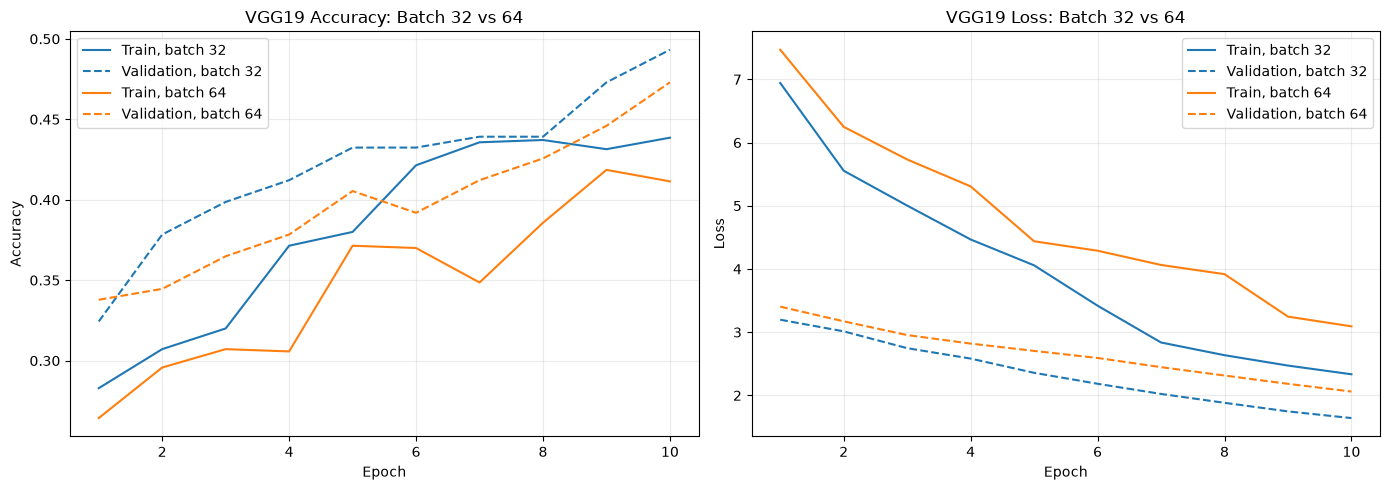

In [31]:
# Compare learning curves from the two independent training runs.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for batch_size, history in histories.items():
    epoch_numbers = range(1, len(history["accuracy"]) + 1)
    line, = axes[0].plot(epoch_numbers, history["accuracy"], label=f"Train, batch {batch_size}")
    axes[0].plot(
        epoch_numbers, history["val_accuracy"], linestyle="--", color=line.get_color(),
        label=f"Validation, batch {batch_size}",
    )
    line, = axes[1].plot(epoch_numbers, history["loss"], label=f"Train, batch {batch_size}")
    axes[1].plot(
        epoch_numbers, history["val_loss"], linestyle="--", color=line.get_color(),
        label=f"Validation, batch {batch_size}",
    )
for ax, metric in zip(axes, ["Accuracy", "Loss"]):
    ax.set_title(f"VGG19 {metric}: Batch 32 vs 64")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## EfficientNetB0: batch 32 and 64, compared with VGG19

 256 inputs, Dense(128), Dropout(0.5), softmax output, split, and final-epoch weight selection. Epochs, seed, and learning rate are read from each saved VGG19 run. EfficientNetB0 receives RGB values in [0, 255] and handles preprocessing internally.


In [1]:
import csv
import json
import time
from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# This section can use previously saved VGG19 artifacts after a kernel restart.
en_lab_dir = next(
    (p.resolve() for p in [Path.cwd(), Path.cwd() / "lab_vgg"]
     if (p / "binary_classification_train.ipynb").is_file()),
    None,
)
if en_lab_dir is None:
    raise FileNotFoundError("Start Jupyter from the repository root or lab_vgg.")
en_labels_file = en_lab_dir / "pet_expression_class_names.json"
if not en_labels_file.is_file():
    raise FileNotFoundError("Run the VGG19 training section first to save class labels and splits.")
en_class_names = json.loads(en_labels_file.read_text(encoding="utf-8"))
en_num_classes = len(en_class_names)
en_batch_sizes = [32, 64]
EN_IMAGE_SIZE = (256, 256)
en_split_dir = en_lab_dir / "preprocess_pet_facial_expression_dataset"

en_vgg_runs = {}
for en_batch in en_batch_sizes:
    en_history_path = en_lab_dir / f"VGG19_batch{en_batch}_history.json"
    if not en_history_path.is_file():
        raise FileNotFoundError(f"Missing {en_history_path.name}; finish VGG19 training first.")
    en_vgg_runs[en_batch] = json.loads(en_history_path.read_text(encoding="utf-8"))

# Match the existing split and RGB loading used for VGG19.
en_train_images = tf.keras.preprocessing.image_dataset_from_directory(
    en_split_dir / "train", labels="inferred", label_mode="int",
    class_names=en_class_names, batch_size=None, image_size=EN_IMAGE_SIZE, shuffle=False,
)
en_num_train_images = len(en_train_images.file_paths)
en_val_images = tf.keras.preprocessing.image_dataset_from_directory(
    en_split_dir / "validation", labels="inferred", label_mode="int",
    class_names=en_class_names, batch_size=None, image_size=EN_IMAGE_SIZE, shuffle=False,
)

def make_efficientnet_datasets(batch_size, seed):
    train = en_train_images.shuffle(
        en_num_train_images, seed=seed, reshuffle_each_iteration=True
    ).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    validation = en_val_images.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return train, validation


Found 700 files belonging to 4 classes.
Found 148 files belonging to 4 classes.


In [2]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam


def build_efficientnetb0_model(num_classes, weights="imagenet", learning_rate=0.0001):
    """Accept RGB pixels in [0, 255]; EfficientNet includes input scaling."""
    if num_classes < 2:
        raise ValueError("At least two expression classes are required.")
    backbone = EfficientNetB0(
        include_top=False, weights=weights, input_shape=(*EN_IMAGE_SIZE, 3)
    )
    backbone.trainable = False
    inputs = layers.Input(shape=(*EN_IMAGE_SIZE, 3))
    # Keep backbone BatchNormalization and stochastic layers in inference mode.
    features = backbone(inputs, training=False)
    features = layers.GlobalAveragePooling2D()(features)
    features = layers.Dense(128, activation="relu")(features)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(num_classes, activation="softmax")(features)
    model = models.Model(inputs, outputs, name="pet_expression_efficientnetb0")
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return model


In [3]:
# Train independent EfficientNetB0 models and save each completed run.
en_histories = {}
en_training_results = []
for en_batch in en_batch_sizes:
    en_settings = en_vgg_runs[en_batch]["summary"]
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(en_settings["seed"])
    en_train_ds, en_val_ds = make_efficientnet_datasets(en_batch, en_settings["seed"])
    en_model = build_efficientnetb0_model(
        en_num_classes, weights="imagenet", learning_rate=en_settings["learning_rate"]
    )
    if en_batch == en_batch_sizes[0]:
        en_model.summary()
    print(f"\nTraining EfficientNetB0, batch {en_batch}, epochs {en_settings['epochs']}")
    en_started = time.perf_counter()
    en_history = en_model.fit(
        en_train_ds, validation_data=en_val_ds, epochs=en_settings["epochs"], shuffle=False
    )
    en_seconds = time.perf_counter() - en_started
    en_weights_path = en_lab_dir / f"TL_EfficientNetB0_pet_expression_batch{en_batch}.weights.h5"
    en_model.save_weights(str(en_weights_path))
    en_histories[en_batch] = {
        name: [float(value) for value in values]
        for name, values in en_history.history.items()
    }
    en_record = {
        "batch_size": en_batch,
        "epochs": en_settings["epochs"],
        "seed": en_settings["seed"],
        "learning_rate": en_settings["learning_rate"],
        "train_accuracy": en_histories[en_batch]["accuracy"][-1],
        "val_accuracy": en_histories[en_batch]["val_accuracy"][-1],
        "train_loss": en_histories[en_batch]["loss"][-1],
        "val_loss": en_histories[en_batch]["val_loss"][-1],
        "training_seconds": en_seconds,
        "weights_file": en_weights_path.name,
    }
    en_training_results.append(en_record)
    en_history_path = en_lab_dir / f"EfficientNetB0_batch{en_batch}_history.json"
    en_history_path.write_text(json.dumps({
        "summary": en_record, "history": en_histories[en_batch],
        "class_names": en_class_names, "image_size": list(EN_IMAGE_SIZE),
        # Preserve every preprocessing layer, including ImageNet-specific scaling.
        "model_json": en_model.to_json(),
    }, indent=2), encoding="utf-8")
    print(f"Saved weights: {en_weights_path}")
    print(f"Saved history: {en_history_path}")
    del en_model, en_history, en_train_ds, en_val_ds



16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 82s 5us/step


Model: "pet_expression_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Training EfficientNetB0, batch 32, epochs 10
Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 411ms/step - accuracy: 0.3014 - loss: 1.3782 - val_accuracy: 0.4392 - val_loss: 1.2827
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 237ms/step - accuracy: 0.5500 - loss: 1.1675 - val_accuracy: 0.5068 - val_loss: 1.1836
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 231ms/step - accuracy: 0.6200 - loss: 1.0457 - val_accuracy: 0.5676 - val_loss: 1.1175
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 234ms/step - accuracy: 0.6714 - loss: 0.9595 - val_accuracy: 0.6081 - val_loss: 1.0602
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 231ms/step - accuracy: 0.7100 - loss: 0.8885 - val_accuracy: 0.6486 - val_loss: 1.0136
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 231ms/step - accuracy: 0.7400 - loss: 0.8277 - val_accuracy: 0.6622 - val_loss: 0.9723
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 237ms/step - accuracy: 0.7614 - loss: 0.7727 - val_accuracy: 0.6892 - val_loss: 0.9347
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 237ms/step - acc

| Model | Batch | Train accuracy | Validation accuracy | Train loss | Validation loss | Seconds |
|---|---|---|---|---|---|---|
| VGG19 | 32 | 0.4386 | 0.4932 | 2.3339 | 1.6408 | 485.1 |
| EfficientNetB0 | 32 | 0.8529 | 0.7432 | 0.6386 | 0.8375 | 59.1 |
| VGG19 | 64 | 0.4114 | 0.4730 | 3.0922 | 2.0608 | 555.4 |
| EfficientNetB0 | 64 | 0.7600 | 0.6689 | 0.7871 | 0.9561 | 58.2 |

Saved: C:\Users\Pc\Documents\GitHub\AI_class\lab_vgg\VGG19_vs_EfficientNetB0_training_comparison.csv


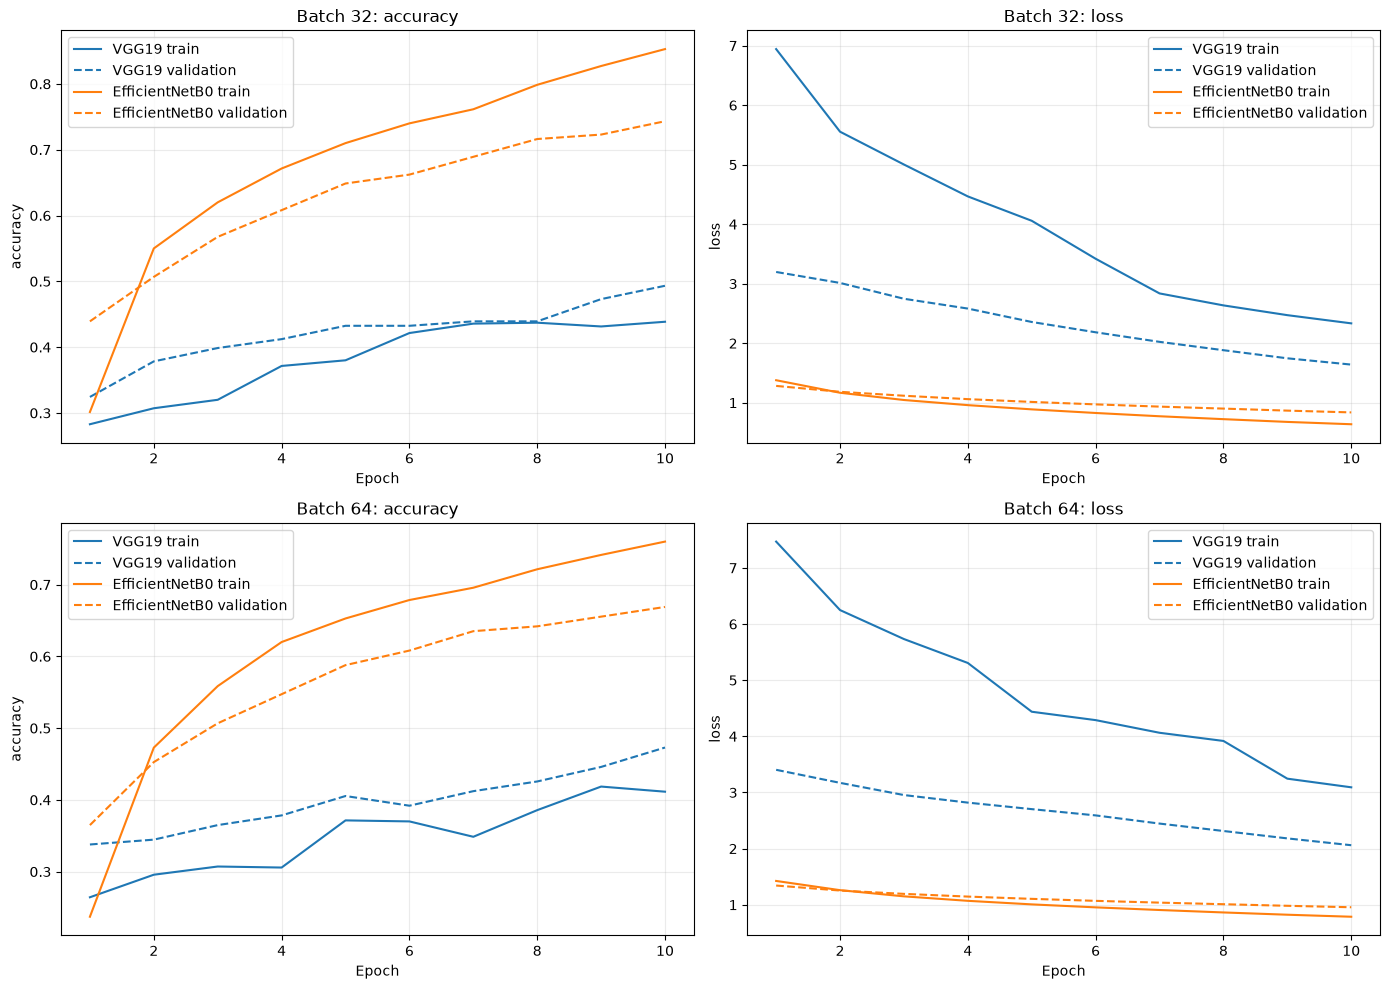

Use the appended test section for held-out classification comparisons.


In [4]:
# Compare all four completed training runs, keeping VGG19 artifacts intact.
en_combined_training = []
for en_batch in en_batch_sizes:
    en_combined_training.append({"model": "VGG19", **en_vgg_runs[en_batch]["summary"]})
    en_combined_training.append({
        "model": "EfficientNetB0",
        **next(row for row in en_training_results if row["batch_size"] == en_batch),
    })
en_comparison_path = en_lab_dir / "VGG19_vs_EfficientNetB0_training_comparison.csv"
with en_comparison_path.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(en_combined_training[0]))
    writer.writeheader()
    writer.writerows(en_combined_training)
en_table = [
    "| Model | Batch | Train accuracy | Validation accuracy | Train loss | Validation loss | Seconds |",
    "|---|---|---|---|---|---|---|",
]
for row in en_combined_training:
    en_table.append(
        f"| {row['model']} | {row['batch_size']} | {row['train_accuracy']:.4f} | "
        f"{row['val_accuracy']:.4f} | {row['train_loss']:.4f} | "
        f"{row['val_loss']:.4f} | {row['training_seconds']:.1f} |"
    )
display(Markdown("\n".join(en_table)))
print(f"Saved: {en_comparison_path}")

# One row of plots per batch size, comparing both architectures' learning curves.
en_fig, en_axes = plt.subplots(len(en_batch_sizes), 2, figsize=(14, 10), squeeze=False)
for index, en_batch in enumerate(en_batch_sizes):
    for model_name, model_history in [
        ("VGG19", en_vgg_runs[en_batch]["history"]),
        ("EfficientNetB0", en_histories[en_batch]),
    ]:
        epoch_numbers = range(1, len(model_history["accuracy"]) + 1)
        for col, metric in enumerate(["accuracy", "loss"]):
            line, = en_axes[index, col].plot(
                epoch_numbers, model_history[metric], label=f"{model_name} train"
            )
            en_axes[index, col].plot(
                epoch_numbers, model_history[f"val_{metric}"], linestyle="--",
                color=line.get_color(), label=f"{model_name} validation",
            )
    for col, metric in enumerate(["accuracy", "loss"]):
        en_axes[index, col].set(title=f"Batch {en_batch}: {metric}", xlabel="Epoch", ylabel=metric)
        en_axes[index, col].legend()
        en_axes[index, col].grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("Use the appended test section for held-out classification comparisons.")
